# Forecasting next-hour PM2.5


**Goal:** predict PM2.5 for the next hour from the last 24 hours of pollution and the latest weather, and beat the simplest possible forecast, "next hour = this hour".

| Step | Checklist item |
|---|---|
| 1 | Load the cleaned data with `src/preprocessing.py` |
| 2 | Feature Engineering: Lags (t-1, t-2, t-3, t-24) and rolling means (6 h, 24 h), in `src/features.py` |
| 3 | Persistence baseline, scored with RMSE and MAE |
| 4 | Main model (XGBoost) plus experiments with different hyperparameters |
| 5 | Model comparison, then save the best model to `models/` |

In [1]:
# Only needed in Google Colab: get the repo so src/ and the data are available.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("beijing-pm25-forecasting-pipeline"):
    !git clone -q https://github.com/teniolaiji/beijing-pm25-forecasting-pipeline.git
    %cd beijing-pm25-forecasting-pipeline
    !pip -q install xgboost

In [2]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

# Find the repo root whether we run from the root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from load_data import load_raw
from preprocessing import clean, MAX_GAP_HOURS
from features import FEATURE_COLUMNS, HISTORY_HOURS, build_features, training_table, next_hour_row

MODEL_DIR = ROOT / "models"
FIG_DIR = ROOT / "outputs" / "figures"
MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
plt.rcParams["figure.figsize"] = (11, 4)
pd.set_option("display.max_colwidth", None)

## 1. Load Data & Clean Gaps

Fetching raw data via `load_raw()`. Running `clean()` to interpolate gaps up to **6 hours**. 

Interpolated points are flagged so we don't accidentally train or evaluate model metrics against synthetic features.

In [3]:
raw = load_raw()
df = clean(raw)
observed = raw.set_index("datetime")["pm25"].notna()

print(f"{len(df):,} hourly rows, {df.index.min()} to {df.index.max()}")
print(f"Missing PM2.5: {raw.pm25.isna().sum():,} before cleaning, "
      f"{df.pm25.isna().sum():,} after filling gaps of <= {MAX_GAP_HOURS} h")

43,824 hourly rows, 2010-01-01 00:00:00 to 2014-12-31 23:00:00
Missing PM2.5: 2,067 before cleaning, 1,817 after filling gaps of <= 6 h


## 2. Features

`training_table()` (in `src/features.py`) builds one row per **target hour t**. Every input comes from hour t-1 or earlier, so the model never sees what it predicts.

| Group | Features | Why (EDA finding) |
|---|---|---|
| Lags | PM2.5 at t-1, t-2, t-3, t-24 | PM2.5 is 0.97 correlated with the previous hour; lag 24 adds the daily cycle |
| Rolling means | Mean PM2.5 over the previous 6 h and 24 h | Shows whether a smog episode is building or clearing |
| Weather at t-1 | dew point, temperature, pressure, wind speed, snow, rain | Wind and rain clear pollution; humid, still air traps it |
| Wind direction at t-1 | one-hot NE, NW, SE, cv | North-west wind brings clean air |
| Calendar | hour, month, day of week | Night-time and winter peaks |

Weather is taken from the previous hour because the current hour's weather is not known when the forecast is made. A rolling mean whose window contains a gap is left empty rather than averaged over fewer hours.

In [4]:
table = training_table(df, observed)
print(f"Rows with complete features and a real target: {len(table):,} of {len(df):,} ({len(table)/len(df):.1%})")
print(f"{len(FEATURE_COLUMNS)} features: {FEATURE_COLUMNS}")
table.head()

Rows with complete features and a real target: 40,756 of 43,824 (93.0%)
19 features: ['pm25_lag1', 'pm25_lag2', 'pm25_lag3', 'pm25_lag24', 'pm25_roll6', 'pm25_roll24', 'dew_point_lag1', 'temperature_lag1', 'pressure_lag1', 'wind_speed_lag1', 'hours_snow_lag1', 'hours_rain_lag1', 'wind_NE', 'wind_NW', 'wind_SE', 'wind_cv', 'hour', 'month', 'dayofweek']


,pm25_lag1,pm25_lag2,pm25_lag3,pm25_lag24,pm25_roll6,pm25_roll24,dew_point_lag1,temperature_lag1,pressure_lag1,wind_speed_lag1,hours_snow_lag1,hours_rain_lag1,wind_NE,wind_NW,wind_SE,wind_cv,hour,month,dayofweek,target
datetime,,,,,,,,,,,,,,,,,,,,
2010-01-03 00:00:00,126.0,156.0,164.0,129.0,153.166667,145.958333,-8.0,-6.0,1027.0,55.43,3.0,0.0,0.0,0.0,1.0,0.0,0,1,6,90.0
2010-01-03 01:00:00,90.0,126.0,156.0,148.0,139.833333,144.333333,-7.0,-6.0,1027.0,58.56,4.0,0.0,0.0,0.0,1.0,0.0,1,1,6,63.0
2010-01-03 02:00:00,63.0,90.0,126.0,159.0,125.500000,140.791667,-8.0,-6.0,1026.0,61.69,5.0,0.0,0.0,0.0,1.0,0.0,2,1,6,65.0
2010-01-03 03:00:00,65.0,63.0,90.0,181.0,110.666667,136.875000,-8.0,-7.0,1026.0,65.71,6.0,0.0,0.0,0.0,1.0,0.0,3,1,6,55.0
2010-01-03 04:00:00,55.0,65.0,63.0,138.0,92.500000,131.625000,-8.0,-7.0,1025.0,68.84,7.0,0.0,0.0,0.0,1.0,0.0,4,1,6,65.0


**Data Leakage check.** If the features really only use the past, changing PM2.5 and the weather at hour t (and after) must leave the features for hour t unchanged.

In [5]:
t = pd.Timestamp("2013-06-10 12:00")
tampered = df.copy()
tampered.loc[t:, ["pm25", "wind_speed", "dew_point"]] += 500

same = build_features(df).loc[t].equals(build_features(tampered).loc[t])
print("Features for", t, "unchanged by the present and future:", same)
assert same

Features for 2013-06-10 12:00:00 unchanged by the present and future: True


## 3. Train, validation and test split by time

Shuffling would put 2014 rows in training, letting the model learn from the future. We used a chronological split to prevent temporal leakage:

- **Train:** 2010 - 2012
- **Validation:** 2013 (tuning hyperparameters tuning and early stopping)
- **Test:** 2014 (final evaluation)

In [6]:
train = table[table.index.year <= 2012]
val = table[table.index.year == 2013]
test = table[table.index.year == 2014]

def X(part):
    return part[FEATURE_COLUMNS].astype(float)

def change(part):
    # What the models learn: how much PM2.5 moves from the previous hour
    return part["target"] - part["pm25_lag1"]

pd.DataFrame({
    "from": [p.index.min().date() for p in (train, val, test)],
    "to": [p.index.max().date() for p in (train, val, test)],
    "rows": [len(p) for p in (train, val, test)],
}, index=["train", "validation", "test"])

,from,to,rows
train,2010-01-03,2012-12-31,23585
validation,2013-01-01,2013-12-31,8630
test,2014-01-01,2014-12-31,8541


## 4. Baseline and metrics

- **RMSE** (µg/m³): typical error, punishing big misses hardest, which matters because the dangerous hours are the spikes
- **MAE** (µg/m³): average size of the error, easiest to explain
- **R²**: share of the variation explained

**Persistence baseline:** "next hour = this hour". PM2.5 barely moves hour to hour, so this is hard to beat.

In [7]:
results = []

def score(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

def record(exp, model, target, params, pred_val, seconds=0.0):
    row = {"experiment": exp, "model": model, "predicts": target, "hyperparameters": params,
           **{f"val_{k}": v for k, v in score(val.target, pred_val).items()},
           "train_seconds": round(seconds, 1)}
    results.append(row)
    print(f"{exp:4s} {model:22s} RMSE {row['val_RMSE']:6.2f}  MAE {row['val_MAE']:6.2f}  R2 {row['val_R2']:.3f}")

record("E0", "Persistence baseline", "-", "-", val.pm25_lag1)

E0   Persistence baseline   RMSE  24.83  MAE  13.18  R2 0.936


## 5. Experiments

**Level or change?** A model can predict the PM2.5 level directly, or predict the *change* from the last hour and add it to the last reading. Tree models such as XGBoost cannot predict values outside the range they were trained on, and PM2.5 spikes as high as 994 µg/m³, so predicting the change should suit them better. E2 and E3 test this directly.

| Run | Model | Predicts | Purpose |
|---|---|---|---|
| E1 | Linear Regression | change | Simple, explainable model |
| E2 | XGBoost, fixed settings | level | Does predicting the level work? |
| E3 | XGBoost, same settings | change | Same model, only the target differs |
| E4 | XGBoost, tuned by grid search | change | Best hyperparameters |

In [8]:
start = time.time()
lin = LinearRegression().fit(X(train), change(train))
record("E1", "Linear Regression", "change", "default",
       val.pm25_lag1 + lin.predict(X(val)), time.time() - start)

FIXED = dict(n_estimators=300, max_depth=6, learning_rate=0.1)

def fit_xgb(params, y_train, y_val, early_stop=True):
    model = XGBRegressor(**params, tree_method="hist", n_jobs=-1, random_state=SEED,
                         early_stopping_rounds=50 if early_stop else None)
    model.fit(X(train), y_train, eval_set=[(X(val), y_val)], verbose=False)
    return model

start = time.time()
xgb_level = fit_xgb(FIXED, train.target, val.target, early_stop=False)
record("E2", "XGBoost", "level", "n_estimators=300, max_depth=6, learning_rate=0.1",
       xgb_level.predict(X(val)), time.time() - start)

start = time.time()
xgb_change = fit_xgb(FIXED, change(train), change(val), early_stop=False)
record("E3", "XGBoost", "change", "n_estimators=300, max_depth=6, learning_rate=0.1",
       val.pm25_lag1 + xgb_change.predict(X(val)), time.time() - start)

E1   Linear Regression      RMSE  23.67  MAE  12.98  R2 0.942


E2   XGBoost                RMSE  28.33  MAE  13.85  R2 0.917


E3   XGBoost                RMSE  24.54  MAE  13.16  R2 0.938


### Hyperparameter tuning (E4)

A grid search over the settings that control how complex each tree is and how fast the model learns. Every combination is trained on 2010 to 2012 and scored on 2013.

The number of trees is not guessed. **Early stopping** keeps adding trees until the 2013 error has not improved for 50 rounds, then keeps the best number.

In [9]:
grid = [
    dict(max_depth=d, learning_rate=lr, min_child_weight=mcw, subsample=s, colsample_bytree=s)
    for d in (3, 5, 7)
    for lr in (0.03, 0.1)
    for mcw in (1, 20)
    for s in (1.0, 0.8)
]

tuning = []
start = time.time()
for params in grid:
    model = fit_xgb({**params, "n_estimators": 3000}, change(train), change(val))
    pred = val.pm25_lag1 + model.predict(X(val))
    tuning.append({**params, "n_estimators": model.best_iteration + 1,
                   **score(val.target, pred)})
print(f"{len(grid)} combinations in {time.time() - start:.0f} s")

tuning = pd.DataFrame(tuning).sort_values("RMSE").reset_index(drop=True)
tuning.round(3).head(10)

24 combinations in 12 s


,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,n_estimators,RMSE,MAE,R2
0,3,0.10,20,0.8,0.8,139,23.400,12.665,0.943
1,5,0.03,20,1.0,1.0,312,23.402,12.625,0.943
2,7,0.10,20,0.8,0.8,55,23.417,12.720,0.943
3,5,0.03,1,0.8,0.8,269,23.421,12.655,0.943
4,3,0.10,20,1.0,1.0,210,23.453,12.691,0.943
5,7,0.03,1,0.8,0.8,191,23.468,12.645,0.943
6,7,0.03,20,1.0,1.0,149,23.469,12.632,0.943
7,7,0.03,20,0.8,0.8,174,23.472,12.647,0.943
8,3,0.03,20,1.0,1.0,444,23.473,12.649,0.943
9,3,0.03,1,0.8,0.8,387,23.478,12.675,0.943


In [10]:
best = tuning.iloc[0]
BEST_PARAMS = {
    "max_depth": int(best.max_depth),
    "learning_rate": float(best.learning_rate),
    "min_child_weight": int(best.min_child_weight),
    "subsample": float(best.subsample),
    "colsample_bytree": float(best.colsample_bytree),
    "n_estimators": int(best.n_estimators),
}

start = time.time()
xgb_best = fit_xgb(BEST_PARAMS, change(train), change(val), early_stop=False)
record("E4", "XGBoost (tuned)", "change", ", ".join(f"{k}={v}" for k, v in BEST_PARAMS.items()),
       val.pm25_lag1 + xgb_best.predict(X(val)), time.time() - start)

E4   XGBoost (tuned)        RMSE  23.40  MAE  12.66  R2 0.943


How sensitive is the model to each setting? Averaging the grid by one hyperparameter at a time shows which choices matter.

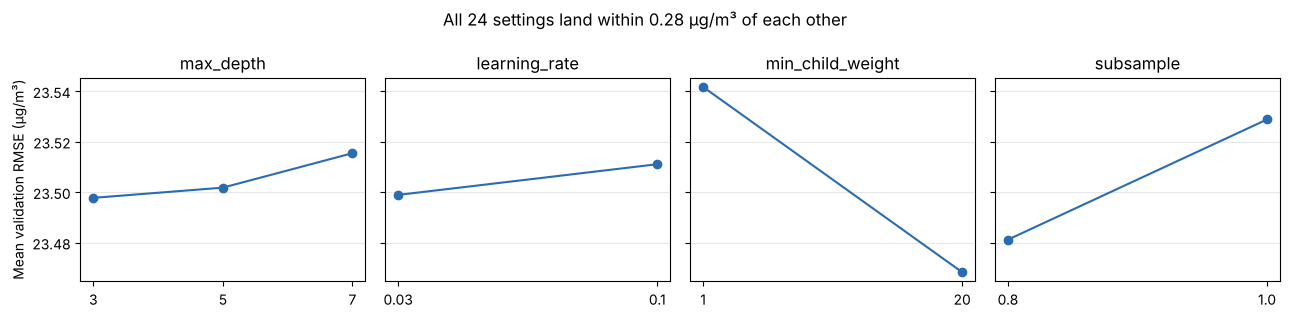

In [11]:
settings = ["max_depth", "learning_rate", "min_child_weight", "subsample"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, col in zip(axes, settings):
    means = tuning.groupby(col)["RMSE"].mean()
    ax.plot(means.index.astype(str), means.values, marker="o", color="#2b6cb0")
    ax.set_title(col)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Mean validation RMSE (µg/m³)")
plt.suptitle(f"All {len(tuning)} settings land within {tuning.RMSE.max() - tuning.RMSE.min():.2f} µg/m³ of each other")
plt.tight_layout()
plt.savefig(FIG_DIR / "tuning_sensitivity.png", dpi=150)
plt.show()

## 6. Experiment table

All scores are on the 2013 validation set. Lower RMSE and MAE are better. `vs_baseline` is the RMSE improvement over persistence.

In [12]:
exp = pd.DataFrame(results)
base_rmse = exp.loc[exp.experiment == "E0", "val_RMSE"].iloc[0]
exp["vs_baseline"] = (1 - exp.val_RMSE / base_rmse).map("{:+.1%}".format)
exp_table = exp.sort_values("val_RMSE").reset_index(drop=True)

exp_table.round(3).to_csv(ROOT / "outputs" / "experiment_table.csv", index=False)
tuning.round(3).to_csv(ROOT / "outputs" / "tuning_grid.csv", index=False)
exp_table.round(3)

,experiment,model,predicts,hyperparameters,val_RMSE,val_MAE,val_R2,train_seconds,vs_baseline
0,E4,XGBoost (tuned),change,"max_depth=3, learning_rate=0.1, min_child_weight=20, subsample=0.8, colsample_bytree=0.8, n_estimators=139",23.400,12.665,0.943,0.2,+5.8%
1,E1,Linear Regression,change,default,23.665,12.984,0.942,0.0,+4.7%
2,E3,XGBoost,change,"n_estimators=300, max_depth=6, learning_rate=0.1",24.542,13.164,0.938,0.9,+1.2%
3,E0,Persistence baseline,-,-,24.830,13.179,0.936,0.0,+0.0%
4,E2,XGBoost,level,"n_estimators=300, max_depth=6, learning_rate=0.1",28.327,13.852,0.917,0.9,-14.1%


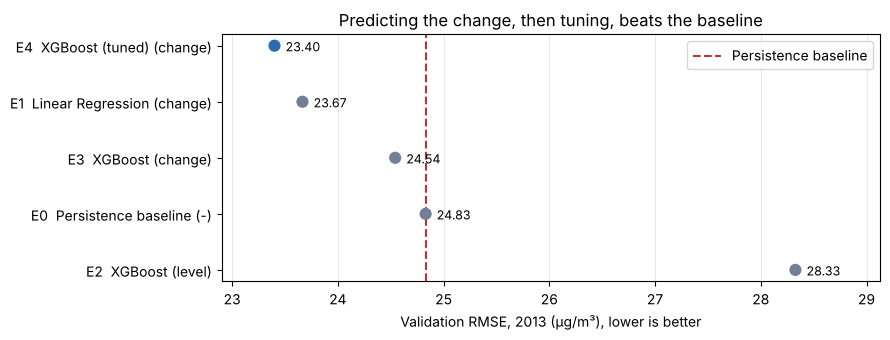

In [13]:
ordered = exp.sort_values("val_RMSE", ascending=False)
colors = ["#2b6cb0" if e == "E4" else "#718096" for e in ordered.experiment]
labels = ordered.experiment + "  " + ordered.model + " (" + ordered.predicts + ")"

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.scatter(ordered.val_RMSE, labels, color=colors, s=60, zorder=3)
for x, y in zip(ordered.val_RMSE, labels):
    ax.annotate(f"{x:.2f}", (x, y), xytext=(8, -4), textcoords="offset points", fontsize=9)
ax.axvline(base_rmse, color="#c53030", linestyle="--", label="Persistence baseline")
ax.grid(axis="x", alpha=0.3)
ax.set_xlim(ordered.val_RMSE.min() - 0.5, ordered.val_RMSE.max() + 0.8)
ax.set_xlabel("Validation RMSE, 2013 (µg/m³), lower is better")
ax.set_title("Predicting the change, then tuning, beats the baseline")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "experiment_comparison.png", dpi=150)
plt.show()

In [14]:
# Numbers quoted in the interpretation below
r = exp.set_index("experiment")
print(f"Level vs change (same XGBoost settings): RMSE {r.val_RMSE.E2:.2f} vs {r.val_RMSE.E3:.2f}")
print(f"Tuning gain over E3: {r.val_RMSE.E3 - r.val_RMSE.E4:.2f} µg/m³")
print(f"Best model vs baseline: {r.vs_baseline.E4}")

Level vs change (same XGBoost settings): RMSE 28.33 vs 24.54
Tuning gain over E3: 1.14 µg/m³
Best model vs baseline: +5.8%


**Reading the table** (the exact numbers are printed above)

- **Predicting the level (E2) is worse than doing nothing.** Its trees cannot go beyond the values they saw in training, so they flatten the 2013 spikes.
- **With the same settings, predicting the change (E3) fixes this** and moves below the baseline.
- **Hyperparameter tuning (E4) further refines RMSE by ~1 µg/m³**. Stopping early prevents overfitting seen in untuned trees.
- **The gain over persistence is modest, as expected** for a one-hour horizon: most of next hour's value is already in this hour. The model's value is in the hours when pollution builds or clears.

## 7. Final model and test score

The tuned settings (E4) are refitted on **2010 to 2013** (train plus validation), so the final model learns from as much history as possible, and then scored **once** on 2014.

In [15]:
train_val = pd.concat([train, val])
final_model = XGBRegressor(**BEST_PARAMS, tree_method="hist", n_jobs=-1, random_state=SEED)
final_model.fit(X(train_val), change(train_val))

test_pred = pd.Series(test.pm25_lag1 + final_model.predict(X(test)), index=test.index)
test_scores = score(test.target, test_pred)
persist_scores = score(test.target, test.pm25_lag1)

pd.DataFrame({"Final model (E4)": test_scores, "Persistence": persist_scores}).T.round(3)

,RMSE,MAE,R2
Final model (E4),20.677,11.412,0.951
Persistence,21.976,11.897,0.944


In [16]:
gain = 1 - test_scores["RMSE"] / persist_scores["RMSE"]
print(f"Test RMSE {test_scores['RMSE']:.2f} vs persistence {persist_scores['RMSE']:.2f} ({gain:+.1%})")

# Where does the model help most? Hours with a big move (|change| > 30 µg/m³).
big = (test.target - test.pm25_lag1).abs() > 30
print(f"Big-move hours: {big.sum():,} ({big.mean():.1%} of 2014). RMSE there: "
      f"model {np.sqrt(mean_squared_error(test.target[big], test_pred[big])):.1f}, "
      f"persistence {np.sqrt(mean_squared_error(test.target[big], test.pm25_lag1[big])):.1f}")

Test RMSE 20.68 vs persistence 21.98 (+5.9%)
Big-move hours: 690 (8.1% of 2014). RMSE there: model 62.3, persistence 68.3


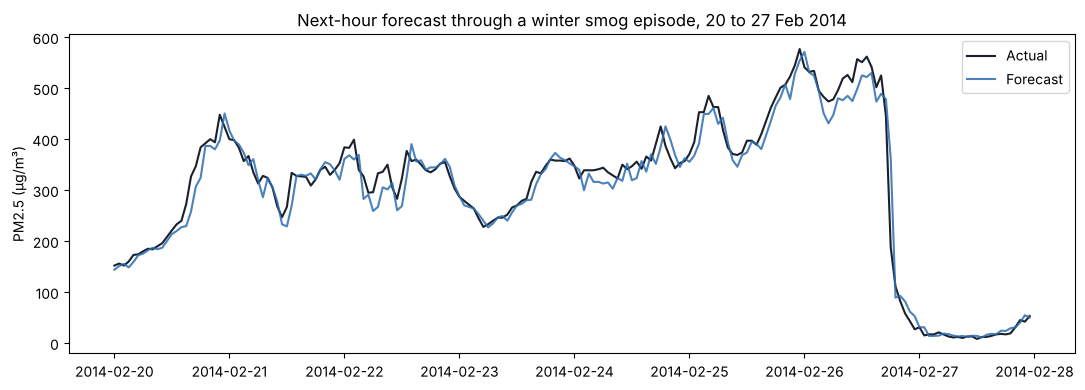

In [17]:
week = slice("2014-02-20", "2014-02-27")
plt.plot(test.target.loc[week], color="#1a202c", label="Actual")
plt.plot(test_pred.loc[week], color="#2b6cb0", alpha=0.85, label="Forecast")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Next-hour forecast through a winter smog episode, 20 to 27 Feb 2014")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "forecast_vs_actual_feb2014.png", dpi=150)
plt.show()

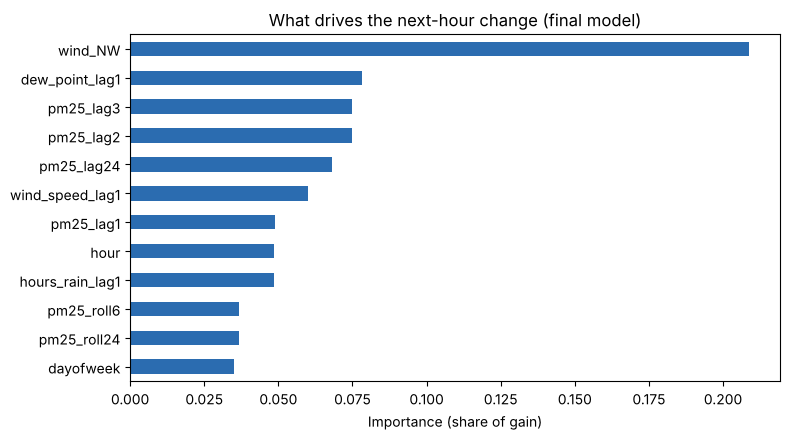

wind_NW           0.209
dew_point_lag1    0.078
pm25_lag3         0.075
pm25_lag2         0.075
pm25_lag24        0.068
dtype: float32


In [18]:
importance = pd.Series(final_model.feature_importances_, index=FEATURE_COLUMNS).sort_values()
importance.tail(12).plot.barh(color="#2b6cb0", figsize=(8, 4.5))
plt.title("What drives the next-hour change (final model)")
plt.xlabel("Importance (share of gain)")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance.png", dpi=150)
plt.show()
print(importance.sort_values(ascending=False).head(5).round(3))

**Reading the results**

- **North-west wind is by far the strongest driver of change** (about a fifth of all importance). The EDA found NW wind brings clean air from the mountains; the model discovered the same physics on its own.
- **Dew point and the recent PM2.5 lags come next.** Humid air traps particles, and the recent trend says whether smog is building.
- **The model helps most when it matters:** on the roughly 8% of 2014 hours where PM2.5 moved by more than 30 µg/m³, its RMSE is about 6 µg/m³ lower than persistence (printed above).
- **Limitation:** when the wind suddenly turns and smog clears, the forecast reacts about an hour late, because the model only knows the weather up to the previous hour. Adding a weather forecast as an input is the natural next step.

## 8. Save the model for `scripts/predict.py`

- `models/pm25_xgb.joblib`: the trained model
- `models/model_meta.json`: feature order, how to turn the output into a forecast, history needed, and scores.

In [19]:
joblib.dump(final_model, MODEL_DIR / "pm25_xgb.joblib")

meta = {
    "model": "XGBRegressor",
    "experiment": "E4",
    "hyperparameters": BEST_PARAMS,
    "target": "change in PM2.5 from the previous hour",
    "forecast": "pm25_lag1 + model output",
    "features": FEATURE_COLUMNS,
    "history_hours_needed": HISTORY_HOURS,
    "preprocessing": f"preprocessing.clean(): interpolate PM2.5 gaps <= {MAX_GAP_HOURS} h",
    "trained_on": f"{train_val.index.min():%Y-%m-%d} to {train_val.index.max():%Y-%m-%d}",
    "test_period": "2014",
    "test_metrics": {k: round(float(v), 3) for k, v in test_scores.items()},
    "test_persistence_metrics": {k: round(float(v), 3) for k, v in persist_scores.items()},
}
(MODEL_DIR / "model_meta.json").write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))

{
  "model": "XGBRegressor",
  "experiment": "E4",
  "hyperparameters": {
    "max_depth": 3,
    "learning_rate": 0.1,
    "min_child_weight": 20,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "n_estimators": 139
  },
  "target": "change in PM2.5 from the previous hour",
  "forecast": "pm25_lag1 + model output",
  "features": [
    "pm25_lag1",
    "pm25_lag2",
    "pm25_lag3",
    "pm25_lag24",
    "pm25_roll6",
    "pm25_roll24",
    "dew_point_lag1",
    "temperature_lag1",
    "pressure_lag1",
    "wind_speed_lag1",
    "hours_snow_lag1",
    "hours_rain_lag1",
    "wind_NE",
    "wind_NW",
    "wind_SE",
    "wind_cv",
    "hour",
    "month",
    "dayofweek"
  ],
  "history_hours_needed": 24,
  "preprocessing": "preprocessing.clean(): interpolate PM2.5 gaps <= 6 h",
  "trained_on": "2010-01-03 to 2013-12-31",
  "test_period": "2014",
  "test_metrics": {
    "RMSE": 20.677,
    "MAE": 11.412,
    "R2": 0.951
  },
  "test_persistence_metrics": {
    "RMSE": 21.976,
    "M

**Sanity check:** reload the saved model and forecast the hour after the dataset ends, the same way `predict.py` will, using only the last 24 hours.

In [20]:
reloaded = joblib.load(MODEL_DIR / "pm25_xgb.joblib")
saved = json.loads((MODEL_DIR / "model_meta.json").read_text())

row = next_hour_row(df.iloc[-saved["history_hours_needed"]:])[saved["features"]]
forecast = row.pm25_lag1.iloc[0] + reloaded.predict(row)[0]

print(f"Last reading {df.index[-1]}: {df.pm25.iloc[-1]:.0f} µg/m³")
print(f"Forecast for {row.index[0]}: {forecast:.0f} µg/m³")

Last reading 2014-12-31 23:00:00: 12 µg/m³
Forecast for 2015-01-01 00:00:00: 12 µg/m³


## Summary

- **Data:** cleaned with the shared `clean()`; 19 leak-free features from `src/features.py`; scored only on real measurements.
- **Approach:** the models predict the hourly *change* in PM2.5, which lets tree models handle spikes beyond their training range.
- **Tuning:** a 24-combination grid with early stopping on 2013, compared in the experiment table against a persistence baseline, Linear Regression and untuned XGBoost.
- **Result:** the tuned XGBoost beats persistence on the unseen 2014 test year (numbers in section 7) and is saved, with its metadata, for the prediction script.